# 05 — Chronos-2 out of the box

The feature-engineered XGBoost of notebook 04 needed 52 hand-made features. Here we do the opposite: give
Chronos-2 nothing but the sales history, with every setting left at its default, and see where it lands.

**What the model is, in three lines.** Chronos-2 is a pretrained forecaster (about 120M parameters, a
T5-style encoder). It cuts the history into patches of 16 days, embeds them as vectors, and outputs the
quantiles of the whole horizon in a single forward pass: no vocabulary, no step-by-step decoding, and the
horizon length is an input. Its point forecast is the median (quantile 0.5).

**Out of the box** means: no covariates, no fine-tuning, cross-learning off (each series is forecast on its
own), and the default context length.

This notebook never imports `xgboost`: on macOS, xgboost and torch each load their own OpenMP library and
the kernel crashes. The XGBoost forecasts are read back from the file saved by notebook 04.

In [1]:
%load_ext autoreload
%autoreload 2

import time
from datetime import timedelta
from importlib.metadata import version

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from m5_chronos2.data import ARTIFACTS_DIR, HORIZON, roster_name
from m5_chronos2.evaluation import actuals, make_windows
from m5_chronos2.metrics import METRICS, compare, join_truth, score
from m5_chronos2.chronos2 import QUANTILE_COLUMNS, cached, forecast, get_pipeline, history, pipeline_limits
from m5_chronos2.plots import MODEL_COLORS, MUTED_TEXT_COLOR, index_plot, plot_by_bucket, plot_fan, use_blog_style

use_blog_style()

## Settings

In [2]:
SAMPLE_SIZE = 500
SEED = 42
NAME = roster_name(SAMPLE_SIZE, SEED)
MODEL_NAME = "chronos2_vanilla"
from m5_chronos2.chronos2 import resolve_device
DEVICE = resolve_device()   # cpu on the laptop, cuda on the tower


In [3]:
sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
truth = actuals(sales)
eval_roster = pl.read_parquet(ARTIFACTS_DIR / f"eval_roster_{NAME}.parquet")
windows = make_windows()
VALIDATION_ORIGIN, TEST_ORIGIN = windows["origin"].to_list()
series_ids = sales["id"].unique().sort().to_list()
PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"

## 1. Load the model and read its limits

Three numbers matter, and they are printed from the loaded model rather than taken from memory: the context
length used when none is given, the largest one the model accepts, and the longest horizon.

In [4]:
for package in ["chronos-forecasting", "torch", "transformers"]:
    print(f"{package:22s} {version(package)}")

start = time.time()
pipeline = get_pipeline(device=DEVICE)
print(f"Model loaded in {time.time() - start:.0f} s")
pipeline_limits(pipeline)

chronos-forecasting    2.3.2
torch                  2.2.2
transformers           4.57.6


/Users/amelien/Desktop/ML/BLOG/m5-chronos2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model loaded in 124 s


{'default_context_length': 2048,
 'model_context_length': 8192,
 'model_prediction_length': 1024,
 'output_patch_size': 16}

## 2. What the model sees

The history of each series up to the origin. Days before the item's first price are missing data (notebook
02): they are dropped, so each series simply starts on its first day on sale. `history` checks that what
remains has no gap, because Chronos-2 assumes a regular daily grid.

The model reads at most the last `context_length` days of each series and **silently ignores the rest**.
How does that compare with the length of our histories?

In [5]:
context = history(sales, VALIDATION_ORIGIN)
lengths = context.group_by("id").agg(pl.len().alias("days"))["days"]

print(f"{lengths.len()} series, history length at the validation origin (days):")
print(f"  min {lengths.min()}, median {lengths.median():.0f}, max {lengths.max()}")
print(f"Context length if none is given: {pipeline.model_context_length}, "
      f"documented default: {pipeline.default_context_length}")
print(f"Series longer than {pipeline.default_context_length} days: {(lengths > pipeline.default_context_length).sum()}")

500 series, history length at the validation origin (days):
  min 184, median 1714, max 1885
Context length if none is given: 8192, documented default: 2048
Series longer than 2048 days: 0


With daily data, every history is shorter than both numbers: out of the box, the model reads the **whole**
history of every series. (With hourly data the same 8,192 steps would be under a year, and the context
length would cut the history.) Reading everything is not necessarily best: notebook 07 measures it.

## 3. Sanity checks, before trusting any number

1. **Batching is not sharing.** With cross-learning off, a series forecast alone and the same series
   forecast inside a batch of 100 must give the same result. If not, the data grid or the series order is wrong.
2. **The point forecast is the median.** The library calls the column `predictions` (and computes it in a
   variable named `mean`); it should equal quantile 0.5.
3. **The context length changes nothing yet**: forecasting with the documented default (2,048 days)
   must give the same result as the model maximum, since no history is that long.
4. **Quantiles in order, no missing value.**

In [6]:
probe_ids = series_ids[:100]
probe_context = history(sales, VALIDATION_ORIGIN, probe_ids)
batched = forecast(probe_context, VALIDATION_ORIGIN, device=DEVICE)
alone = forecast(history(sales, VALIDATION_ORIGIN, probe_ids[:1]), VALIDATION_ORIGIN, device=DEVICE)

def largest_gap(a, b):
    return np.abs(a.select(["y_pred"] + QUANTILE_COLUMNS).to_numpy() - b.select(["y_pred"] + QUANTILE_COLUMNS).to_numpy()).max()

gap_batch = largest_gap(batched.filter(pl.col("id") == probe_ids[0]), alone)
print(f"1. alone vs inside a batch of 100: largest difference {gap_batch:.1e} units")

gap_median = (batched["y_pred"] - batched["q0.5"]).abs().max()
print(f"2. largest |y_pred - q0.5|: {gap_median:.1e}")

default_context = forecast(probe_context, VALIDATION_ORIGIN, context_length=pipeline.default_context_length, device=DEVICE)
gap_context = largest_gap(batched, default_context)
print(f"3. context {pipeline.default_context_length} vs model maximum: largest difference {gap_context:.1e} units")

quantiles = batched.select(QUANTILE_COLUMNS).to_numpy()
crossing = (np.diff(quantiles, axis=1) < -1e-9).any(axis=1).mean()
print(f"4. missing values: {np.isnan(quantiles).sum()}, rows with crossing quantiles: {crossing:.1%}")

assert gap_batch < 1e-3 and gap_median < 1e-9 and gap_context < 1e-3

1. alone vs inside a batch of 100: largest difference 3.0e-07 units
2. largest |y_pred - q0.5|: 0.0e+00
3. context 2048 vs model maximum: largest difference 0.0e+00 units
4. missing values: 0, rows with crossing quantiles: 19.1%


## 4. Forecast both windows

All 500 series, both origins. The forecasts are saved in the standard format (same file layout as the
baselines and XGBoost); a second run of the notebook reads them back instead of recomputing.

In [7]:
def vanilla_forecasts():
    parts = []
    for origin in windows["origin"].to_list():
        start = time.time()
        parts.append(forecast(history(sales, origin), origin, device=DEVICE))
        print(f"  origin {origin}: {len(series_ids)} series in {time.time() - start:.0f} s")
    return pl.concat(parts)

predictions = cached(PREDICTIONS_DIR / f"{MODEL_NAME}_{NAME}.parquet", vanilla_forecasts)

expected_rows = len(series_ids) * HORIZON * windows.height
assert predictions.height == expected_rows, f"{predictions.height} rows, expected {expected_rows}"
predictions.head()

  origin 2016-03-27: 500 series in 206 s
  origin 2016-04-24: 500 series in 178 s
  computed chronos2_vanilla_n500_seed42.parquet in 383 s


id,origin,date,y_pred,q0.1,q0.2,q0.3,q0.4,q0.5,q0.6,q0.7,q0.8,q0.9
str,date,date,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-28,0.004483,0.0,0.0,0.001943,0.003841,0.004483,0.004609,0.003795,0.033539,0.541382
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-29,0.003772,0.0,0.0,0.001631,0.003685,0.003772,0.003703,0.00583,0.036768,0.597865
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-30,0.003394,0.0,0.0,0.000785,0.002036,0.003394,0.002472,0.004588,0.033845,0.603264
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-31,0.003284,0.0,0.0,0.001585,0.003803,0.003284,0.003548,0.005799,0.037289,0.591623
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-04-01,0.004035,0.0,0.0,0.001101,0.003307,0.004035,0.00511,0.005585,0.035876,0.602626


## 5. Scores

Same evaluation roster and metrics as notebooks 03 and 04.

Two points to keep in mind when reading the table:
- XGBoost and the baselines give a point forecast only, so their WQL is WMAPE / 100 (notebook 03, check 3).
  WQL rewards the extra information carried by Chronos-2's quantiles; **the fair comparison with XGBoost is
  on MAE, WMAPE and P90.**
- Chronos-2's point forecast is a median; XGBoost was trained on squared error, so it estimates a mean. On
  absolute-error metrics (MAE, WMAPE) the median is the optimal point forecast, which gives Chronos-2 a
  structural edge on those two metrics.

In [8]:
model_names = ["zero", "seasonal_naive", "moving_average_28d", "xgboost_btrotta", MODEL_NAME]
scored = {
    model: join_truth(pl.read_parquet(PREDICTIONS_DIR / f"{model}_{NAME}.parquet"), truth, eval_roster)
    .join(windows.select("origin", "role"), on="origin")
    for model in model_names
}
compare(scored, by="role").select(["role", "model", "n_series"] + METRICS).sort("role", "WMAPE")

role,model,n_series,MAE,WMAPE,P90,WQL,RQL
str,str,u32,f64,f64,f64,f64,f64
"""test""","""chronos2_vanilla""",485,0.869666,70.010461,2.101769,0.550018,17.777543
"""test""","""xgboost_btrotta""",485,0.948566,76.362099,2.060481,0.763621,36.824994
"""test""","""moving_average_28d""",485,0.963718,77.58187,2.178571,0.775819,37.974645
"""test""","""seasonal_naive""",485,1.176215,94.688482,3.0,0.946885,46.04778
"""test""","""zero""",485,1.242194,100.0,3.0,1.0,20.0
"""validation""","""chronos2_vanilla""",473,0.879784,70.61731,2.212585,0.558412,18.094016
"""validation""","""xgboost_btrotta""",473,0.98117,78.755239,2.13098,0.787552,38.050116
"""validation""","""moving_average_28d""",473,0.991549,79.588312,2.285714,0.795883,39.114156
"""validation""","""seasonal_naive""",473,1.202658,96.533333,3.0,0.965333,46.572121


Change relative to XGBoost, validation window, in % (negative: lower error than XGBoost).

In [9]:
validation = {model: table.filter(pl.col("role") == "validation") for model, table in scored.items()}
change_columns = [f"{metric}_change_%" for metric in ["MAE", "WMAPE", "P90"]]
compare(validation, reference="xgboost_btrotta").select(["model"] + change_columns)

model,MAE_change_%,WMAPE_change_%,P90_change_%
str,f64,f64,f64
"""zero""",26.97568,26.97568,40.780297
"""seasonal_naive""",22.573856,22.573856,40.780297
"""moving_average_28d""",1.0578,1.0578,7.261179
"""xgboost_btrotta""",0.0,0.0,0.0
"""chronos2_vanilla""",-10.333191,-10.333191,3.829479


### By horizon

Validation window. Naive baselines in gray.

/var/folders/k4/pclq47c50r78wfcdxrrbr27c0000gn/T/ipykernel_16329/4116421897.py:3: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


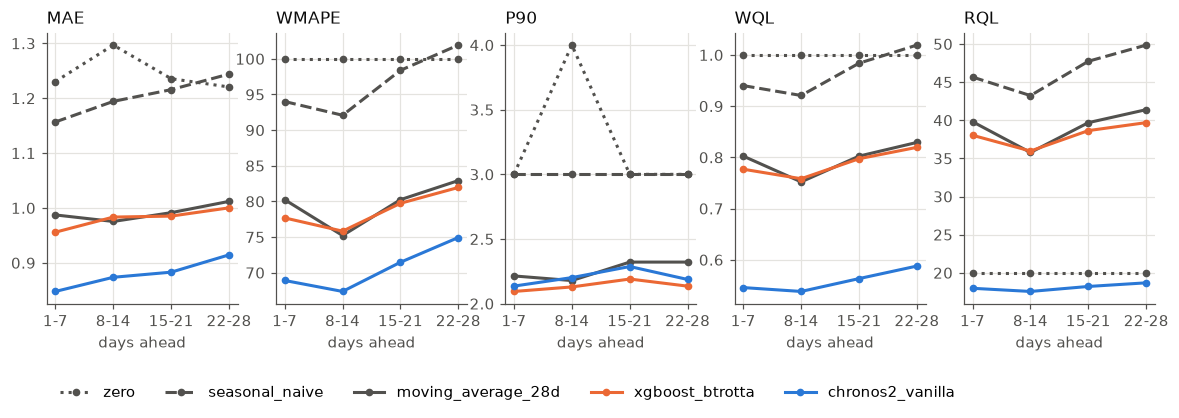

In [10]:
by_bucket = compare(validation, by="horizon_bucket")
fig, axes = plot_by_bucket(by_bucket, METRICS)
fig.tight_layout()
plt.show()

### Series by series: Chronos-2 vs XGBoost

Symmetric relative difference in WMAPE per series (WMAPE rather than WQL, so that the comparison stays
point forecast vs point forecast), series sorted by sales volume in the window.

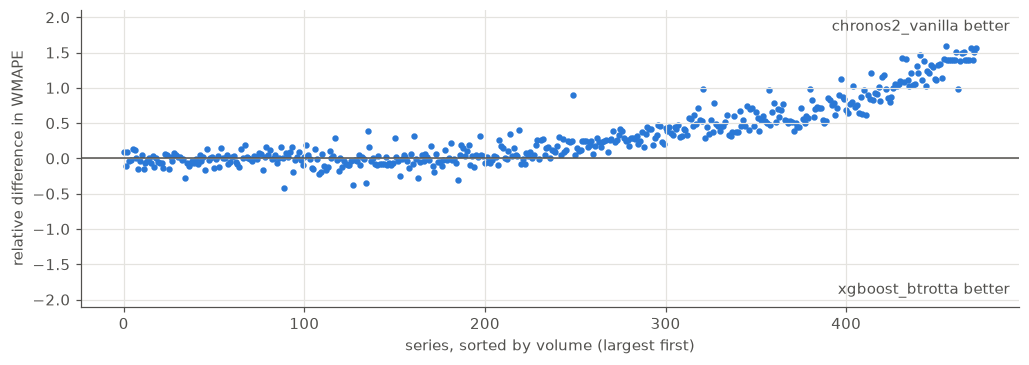

chronos2_vanilla has the lower WMAPE on 75% of series


In [11]:
def per_series(model, metric):
    return score(validation[model], by="id").select("id", pl.col(metric).alias(f"{metric}_{model}"))

volume = validation[MODEL_NAME].group_by("id").agg(pl.col("y").sum().alias("volume"))
per_series_wmape = (
    per_series("xgboost_btrotta", "WMAPE")
    .join(per_series(MODEL_NAME, "WMAPE"), on="id")
    .join(volume, on="id")
)

fig, ax = plt.subplots(figsize=(11, 3.5))
share = index_plot(ax, per_series_wmape, "WMAPE", "xgboost_btrotta", MODEL_NAME, order_by="volume")
plt.show()
print(f"{MODEL_NAME} has the lower WMAPE on {share:.0%} of series")

## 6. What the forecasts look like

Four series of the validation window, picked by sales volume (98th, 75th, 50th and 25th percentile of the
scored series). Gray: the last 12 weeks of history. Blue: Chronos-2's median and quantile bands. Orange:
XGBoost. Dots: what actually sold.

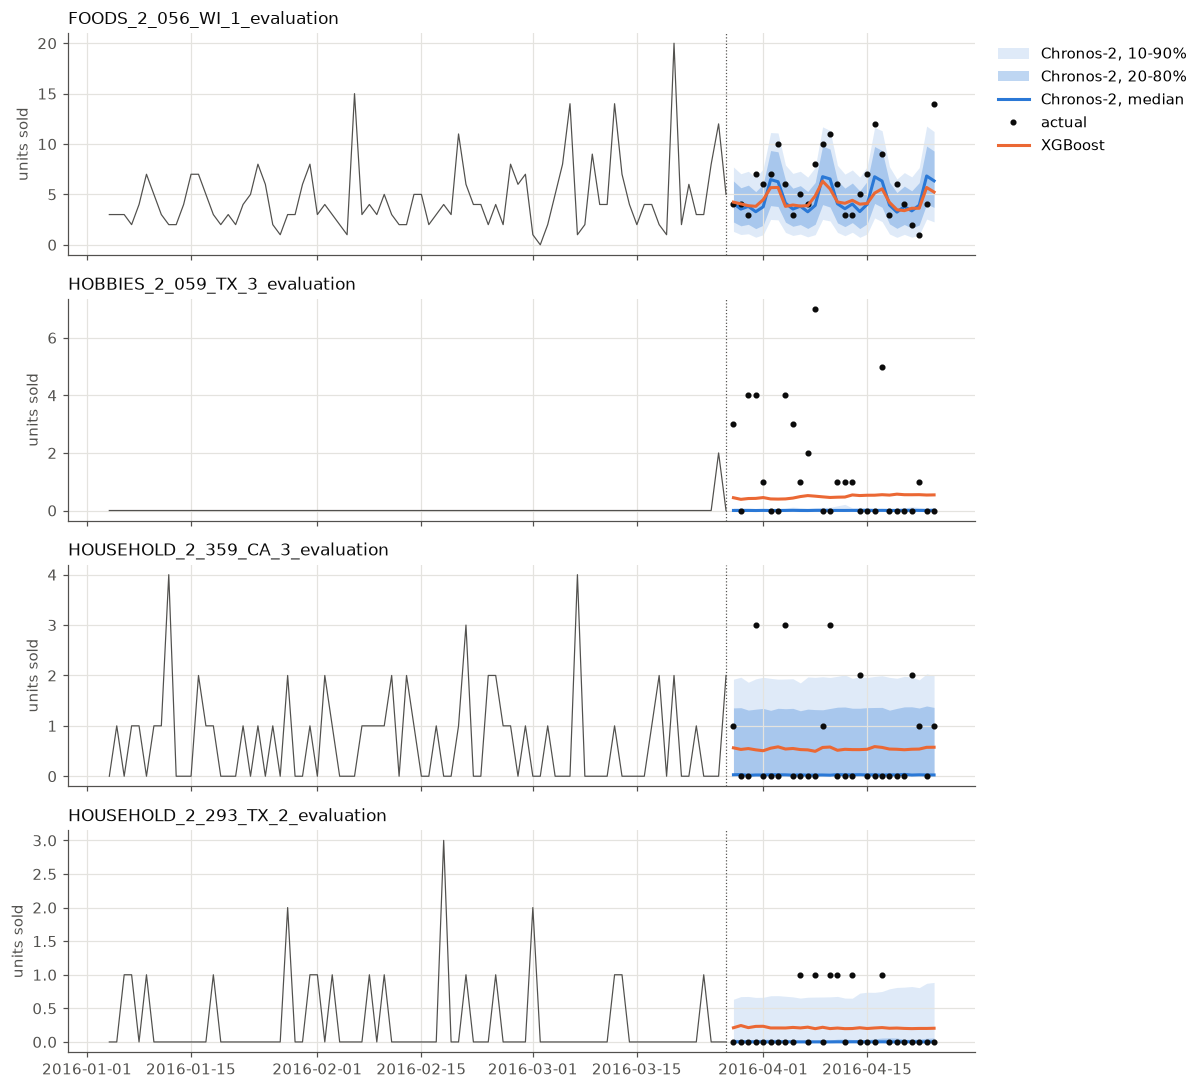

In [12]:
SHOW_DAYS = 84
ranked = volume.sort("volume")
example_ids = [ranked["id"][int(level * (ranked.height - 1))] for level in (0.98, 0.75, 0.5, 0.25)]
xgboost_validation = pl.read_parquet(PREDICTIONS_DIR / f"xgboost_btrotta_{NAME}.parquet").filter(
    pl.col("origin") == VALIDATION_ORIGIN
)

fig, axes = plt.subplots(len(example_ids), 1, figsize=(11, 10), sharex=True)
for ax, series_id in zip(axes, example_ids):
    one = truth.filter(pl.col("id") == series_id)
    past = one.filter(pl.col("date") <= VALIDATION_ORIGIN, pl.col("date") > VALIDATION_ORIGIN - timedelta(days=SHOW_DAYS))
    actual = one.filter(pl.col("date") > VALIDATION_ORIGIN, pl.col("date") <= VALIDATION_ORIGIN + timedelta(days=HORIZON))
    chronos = predictions.filter(pl.col("id") == series_id, pl.col("origin") == VALIDATION_ORIGIN)
    plot_fan(ax, past, chronos, actual, color=MODEL_COLORS[MODEL_NAME], label="Chronos-2")
    xgb_one = xgboost_validation.filter(pl.col("id") == series_id)
    ax.plot(xgb_one["date"].to_numpy(), xgb_one["y_pred"].to_numpy(), color=MODEL_COLORS["xgboost_btrotta"], label="XGBoost")
    ax.axvline(VALIDATION_ORIGIN, color=MUTED_TEXT_COLOR, linewidth=0.8, linestyle=":")
    ax.set_title(series_id, loc="left")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

## Notes

*Your observations here.*